# Breast Cancer Diagnosis Classification

**Question:** How well can cell-nucleus measurements distinguish malignant from benign samples? Train/test split is stratified and scaling is fitted only on training data.

**Dataset:** Wisconsin Diagnostic Breast Cancer, 569 samples and 30 numeric features. Educational use only; not for clinical decisions.

## Load and audit data

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
df=pd.read_csv('breast_cancer_wisconsin.csv')
print(df.shape, df.isna().sum().sum(), df.duplicated().sum())
print(df.diagnosis.value_counts())
df.head()

(569, 31) 0 0
diagnosis
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## Model training and held-out evaluation


 Logistic Regression ROC-AUC: 0.996
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



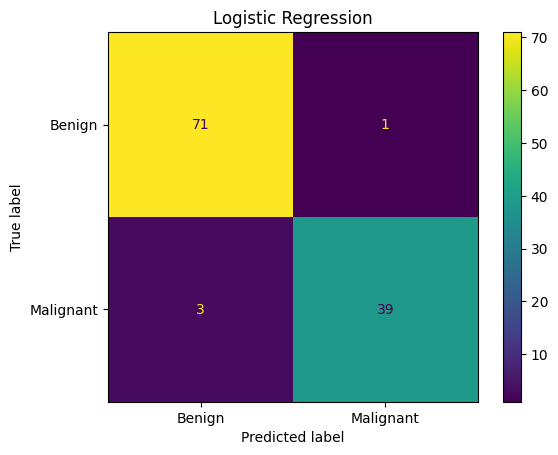


 Random Forest ROC-AUC: 0.994
              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



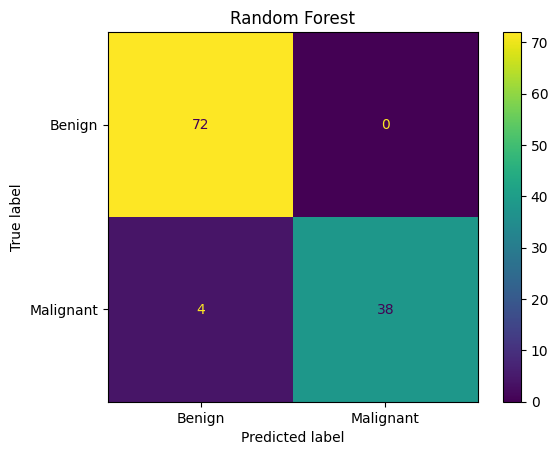

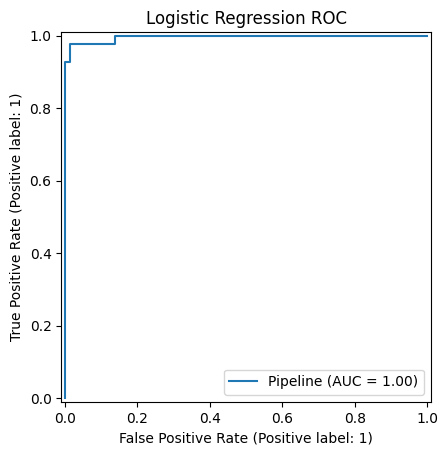

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
X=df.drop(columns='diagnosis'); y=(df.diagnosis==0).astype(int) # malignant is positive
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
models={'Logistic Regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)), 'Random Forest':RandomForestClassifier(n_estimators=150,random_state=42)}
for name,model in models.items():
 model.fit(X_train,y_train)
 pred=model.predict(X_test);prob=model.predict_proba(X_test)[:,1]
 print('\n',name,'ROC-AUC:',round(roc_auc_score(y_test,prob),3))
 print(classification_report(y_test,pred,target_names=['Benign','Malignant']))
 ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=['Benign','Malignant'])
 plt.title(name);plt.show()
RocCurveDisplay.from_estimator(models['Logistic Regression'],X_test,y_test)
plt.title('Logistic Regression ROC');plt.show()

## Interpretation

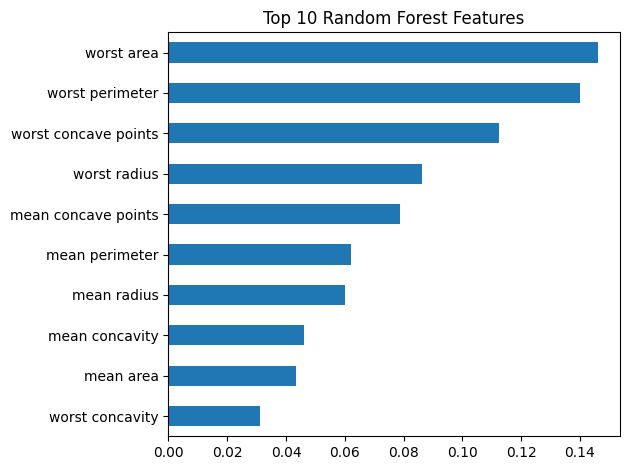

Higher scores indicate useful predictors, not causal effects.


In [3]:
model=models['Random Forest']
importance=pd.Series(model.feature_importances_,index=X.columns).sort_values(ascending=False).head(10)
importance.sort_values().plot.barh(title='Top 10 Random Forest Features');plt.tight_layout();plt.show()
print('Higher scores indicate useful predictors, not causal effects.')

## Limitations
Small, curated dataset; no external clinical validation. Performance cannot be generalized to patient care.